# Persistence features for residual-reversal regimes

October 29, 2026. [Full findings](experiments/equity_persistence_regimes/README.md), [fixed specification](experiments/equity_persistence_regimes/specification.json), [source](experiments/equity_persistence_regimes.py), [proposal and conceptual distinctions](PERSISTENCE_REGIME_IDEAS.md).

**Result:** neither stock-loading nor lagged-state persistence features established an incremental benefit over the same simple forecasting model. The stock-loading version has a modest favorable later trading estimate, with an interval spanning zero. The lagged version adds almost no later trading mean and has worse point forecast error. The controls do establish that the two point objects preserve different distinctions.

This is a past-only walk-forward experiment on already examined history and a current-survivor universe. All performance is gross/pre-fee. The original daily strategy and its data/results are preserved; only an active/flat gate is tested.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display,Image
cwd=Path.cwd()
candidates=[cwd,cwd/"TDA_Research",cwd/"Senior-Fall"/"TDA_Research",*cwd.parents]
project=next(p for p in candidates if (p/"START_HERE.md").is_file() and (p/"equity").is_dir())
out=project/"equity"/"experiments"/"equity_persistence_regimes"
result=json.loads((out/"summary.json").read_text())
audit=json.loads((out/"independent_audit.json").read_text())
features=pd.read_csv(out/"state_features_and_targets.csv")
predictions=pd.read_csv(out/"walk_forward_predictions.csv")
forecast=pd.read_csv(out/"forecast_metrics.csv")
performance=pd.read_csv(out/"gate_performance.csv")
comparisons=pd.read_csv(out/"paired_incremental_comparisons.csv")
calibration=pd.read_csv(out/"sign_calibration.csv")
assert all(result["checks"].values()) and all(audit["checks"].values())
print("Reference stocks:",result["reference_stock_count"])
print("Feature anchors:",result["feature_anchors"],"| forecasts:",result["predictions"])
print("First forecast:",result["first_prediction"])
print("Complete forecast targets:",result["forecast_scores_by_period"])
print("Calendar executions:",result["calendar_days_by_period"])

Reference stocks: 182
Feature anchors: 490 | forecasts: 379
First forecast: 2019-04-18
Complete forecast targets: {'boundary': 4, 'development': 233, 'later': 138}
Calendar executions: {'development': 1183, 'later': 708}


## 1. The fixed task and the two point objects

The target is the mean gross daily return of the **next twenty daily trades** of the existing 120-session SPY-plus-three-PC strategy. It is not a twenty-session frozen stock position. Forecasts update every five sessions. A positive forecast turns on the original daily strategy for the next five sessions; a nonpositive forecast stays flat. Flat days remain in the calendar return series.

The **stock cloud** puts 182 fixed reference stocks in three eigenvalue-weighted loading coordinates. The **lagged-state cloud** puts 119 adjacent pairs of whitened factor-score days in six coordinates. Whitening gives each retained factor unit historical variance. Both clouds are normalized by median pair distance; those unnormalized distances are also simple-model inputs.

The reference names were fixed from the first formation's 272 prior returns, not future completeness. The broader strategy can still admit new stocks as their history arrives. The current-survivor origin of the candidate list remains a limitation.

Three added features per object summarize finite H0 death quantiles and H1 lifetimes. The infinite H0 interval is counted separately, never included in a finite lifetime norm.

finite_intervals      essential_intervals    
                              min  max                 min max
object dimension                                              
lag    0                      118  118                   1   1
       1                       35   83                   0   0
stock  0                      181  181                   1   1
       1                       43   82                   0   0

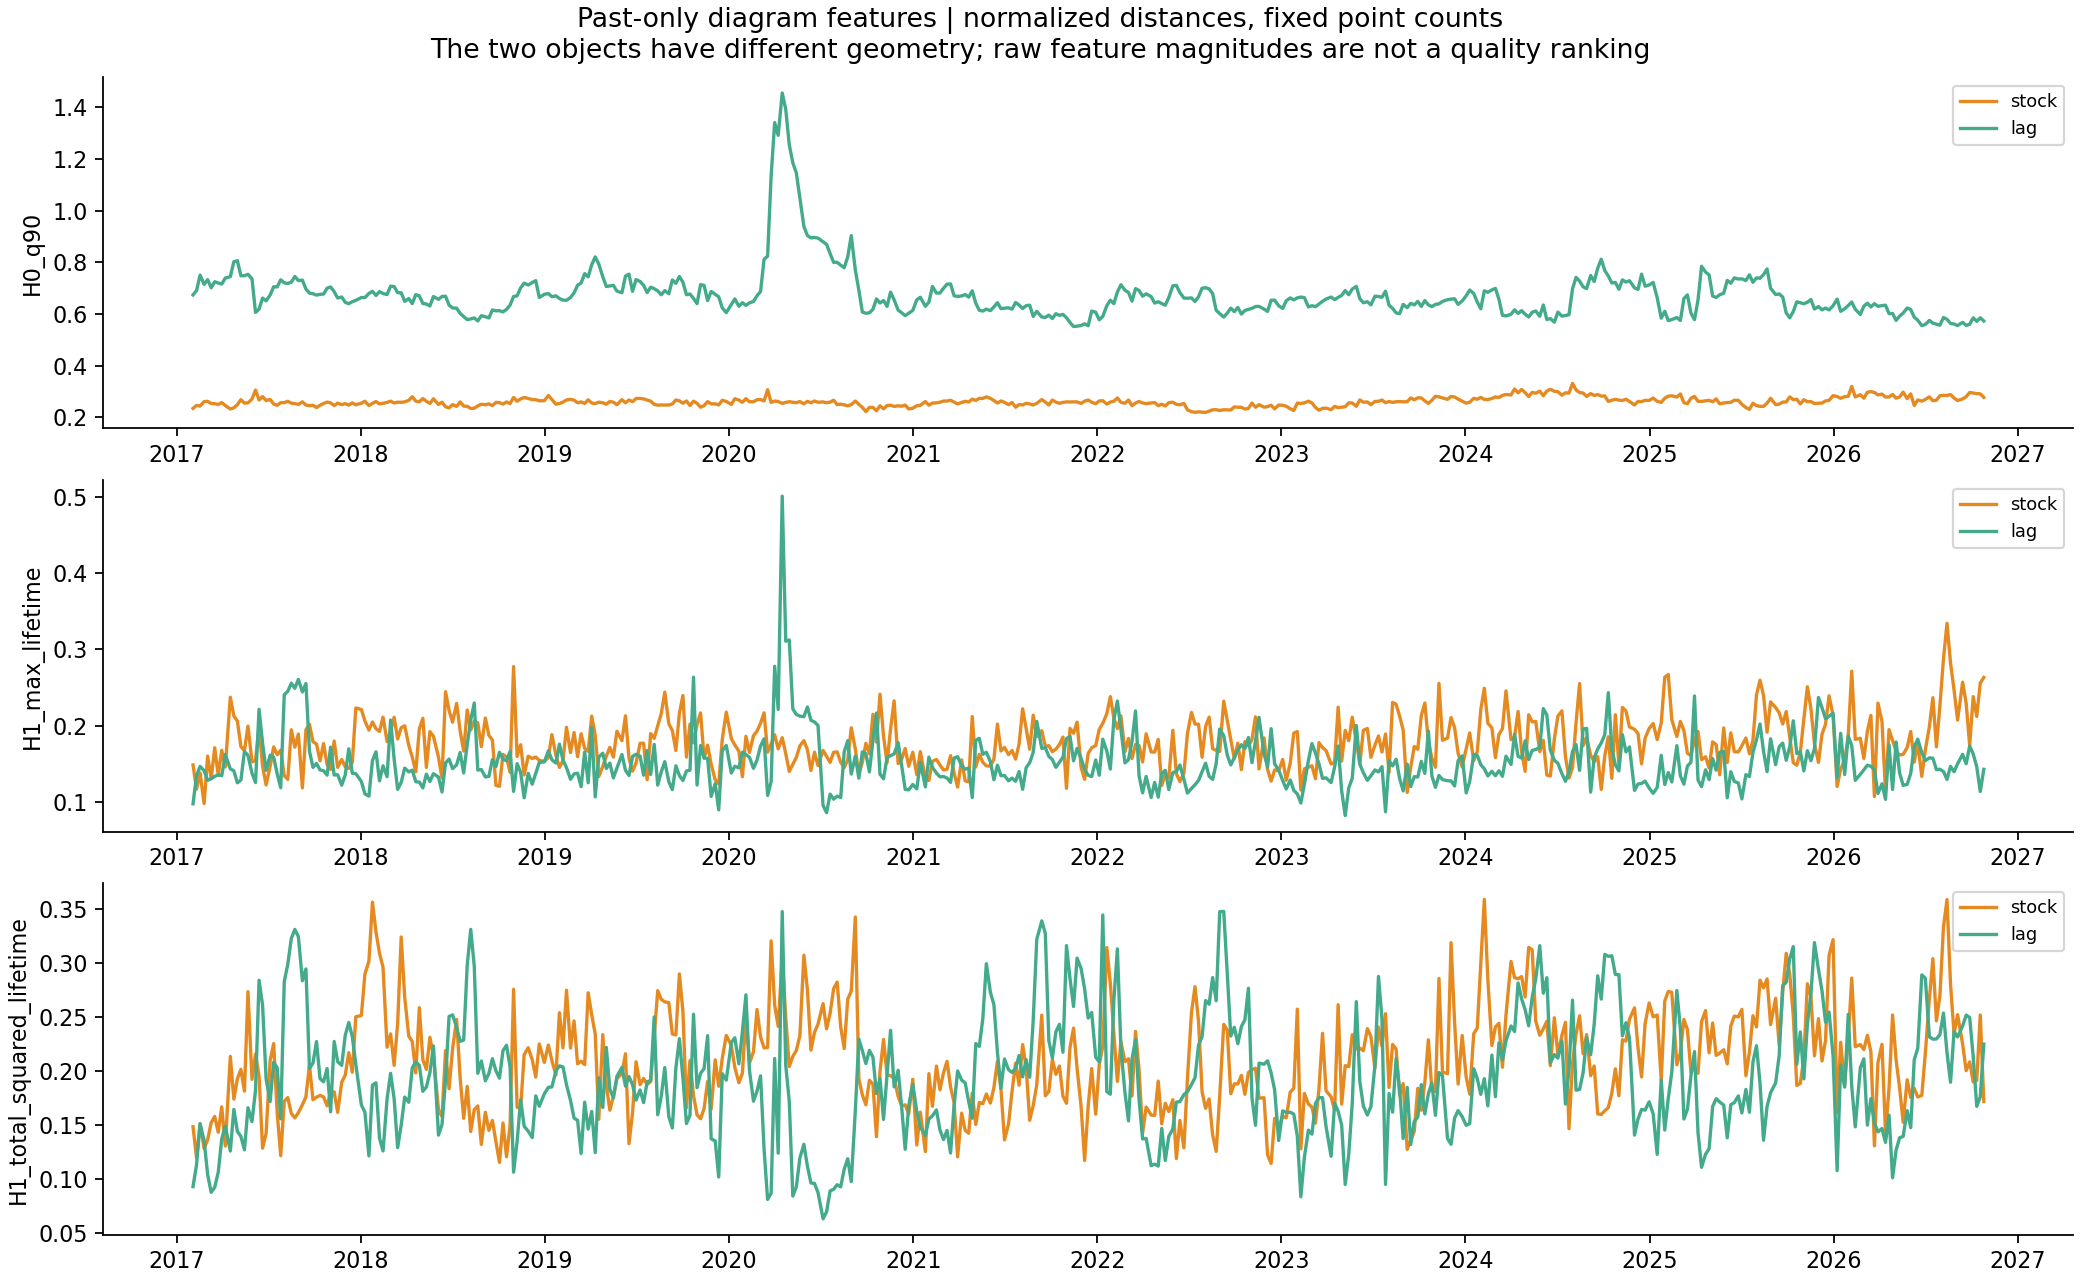

In [2]:
intervals=pd.read_csv(out/"persistence_intervals.csv.gz")
counts=intervals.groupby(["anchor","object","dimension"]).agg(
    intervals=("birth","size"),finite_intervals=("death",lambda x:int(x.notna().sum())),
    essential_intervals=("death",lambda x:int(x.isna().sum()))).reset_index()
counts.to_csv(out/"diagram_interval_counts.csv",index=False)
assert (counts.loc[counts.dimension.eq(0),"essential_intervals"]==1).all()
display(counts.groupby(["object","dimension"])[["finite_intervals","essential_intervals"]].agg(["min","max"]))
display(Image(filename=str(out/"05_persistence_features.png")))

## 2. What the controls show

Shuffling historical days together across stocks and SPY preserves the stock correlation matrix. Stock-loading diagrams stay unchanged; lagged-state diagrams change because different days become neighbors in time. Uniformly scaling returns also leaves the normalized diagrams unchanged.

**Reversing time leaves both diagrams unchanged.** For one-lag states, reversal swaps the two coordinate blocks and reorders points, preserving all distances. So this construction can recognize different transition geometry without retaining a forward arrow of time. It does not itself predict a return direction.

These are first-window representation controls, not profitable-state discoveries. Spectral concentration and lag-one dependence are included in the simple model so diagram features must add something beyond those conventional temporal summaries.

In [3]:
controls=pd.read_csv(out/"representation_controls.csv").set_index("control")
display(controls[["residual_mean_corr","residual_pc1_share","factor_lag1_acf_mean","factor_dominant_power_share_mean",
    "stock_H0_q90","stock_H1_max_lifetime","lag_H0_q90","lag_H1_max_lifetime"]].round(6))
for key in result["configuration"]["stock_features"]:
    assert np.isclose(controls.loc["original",key],controls.loc["joint_rows_shuffled",key],atol=2e-5)
print("Scale, shuffle, and time-reversal checks passed.")

Scale, shuffle, and time-reversal checks passed.


,residual_mean_corr,residual_pc1_share,factor_lag1_acf_mean,factor_dominant_power_share_mean,stock_H0_q90,stock_H1_max_lifetime,lag_H0_q90,lag_H1_max_lifetime
control,,,,,,,,
original,0.004603,0.139472,0.075581,0.057871,0.23491,0.148433,0.674214,0.097585
joint_rows_shuffled,0.004603,0.139472,-0.020470,0.064040,0.23491,0.148433,0.677680,0.143690
time_reversed,0.004603,0.139472,0.075581,0.057871,0.23491,0.148433,0.674214,0.097585
returns_times_three,0.004603,0.139472,0.075581,0.057871,0.23491,0.148433,0.674214,0.097585


## 3. Does persistence improve the forecast?

**HistoryMean** predicts the mean of previously completed targets. **Simple** uses volatility, correlation, PC shares, lag dependence, spectral concentration, trailing strategy returns, stock count, and cloud scales. The two augmented models add three diagram summaries to those identical inputs.

The fitted models use ridge regression: a linear forecast with a fixed penalty shrinking large coefficients. The penalty and zero trading threshold are fixed in advance. Training expands only over completed prior labels, and feature means/scales are fitted only on that training set. At least 104 valid completed labels are required; these overlapping targets are not 104 independent months.

**MSE means average squared forecast error; lower is better.** Later MSE is 32.277 for HistoryMean, 33.347 for Simple, 32.812 with stock PD, and 34.493 with lag PD. Both PD-minus-simple intervals include zero. All complex models have worse point MSE than HistoryMean later; this is not a claim of statistically reliable inferiority.

The realized target line below is displayed afterward for evaluation. It is never passed into that date's fitting or trade decision. Later models can learn from earlier completed 2024+ outcomes, so this is an online chronological exercise, not a model frozen at 2023.

,period,model,forecasts,MSE_bps_squared,MSE_low,MSE_high,MAE_bps,MSE_skill_vs_HistoryMean,mean_forecast_bps,mean_target_bps
0,development,HistoryMean,233,79.27837,28.70982,138.18448,5.90110,0.00000,-0.00944,-0.19816
1,development,Simple,233,71.15267,30.48562,126.46563,5.75414,0.10250,0.31721,-0.19816
2,development,SimplePlusStockPD,233,71.42256,31.23688,126.61989,5.78725,0.09909,0.33782,-0.19816
3,development,SimplePlusLagPD,233,70.17828,28.44048,127.51636,5.64215,0.11479,-0.06117,-0.19816
4,later,HistoryMean,138,32.27741,22.31830,44.55901,4.69351,0.00000,0.06408,1.14186
5,later,Simple,138,33.34713,22.70586,44.76754,4.72975,-0.03314,0.52643,1.14186
6,later,SimplePlusStockPD,138,32.81164,22.00189,44.70502,4.70062,-0.01655,0.67565,1.14186
7,later,SimplePlusLagPD,138,34.49261,23.69154,47.19988,4.81233,-0.06863,0.36957,1.14186


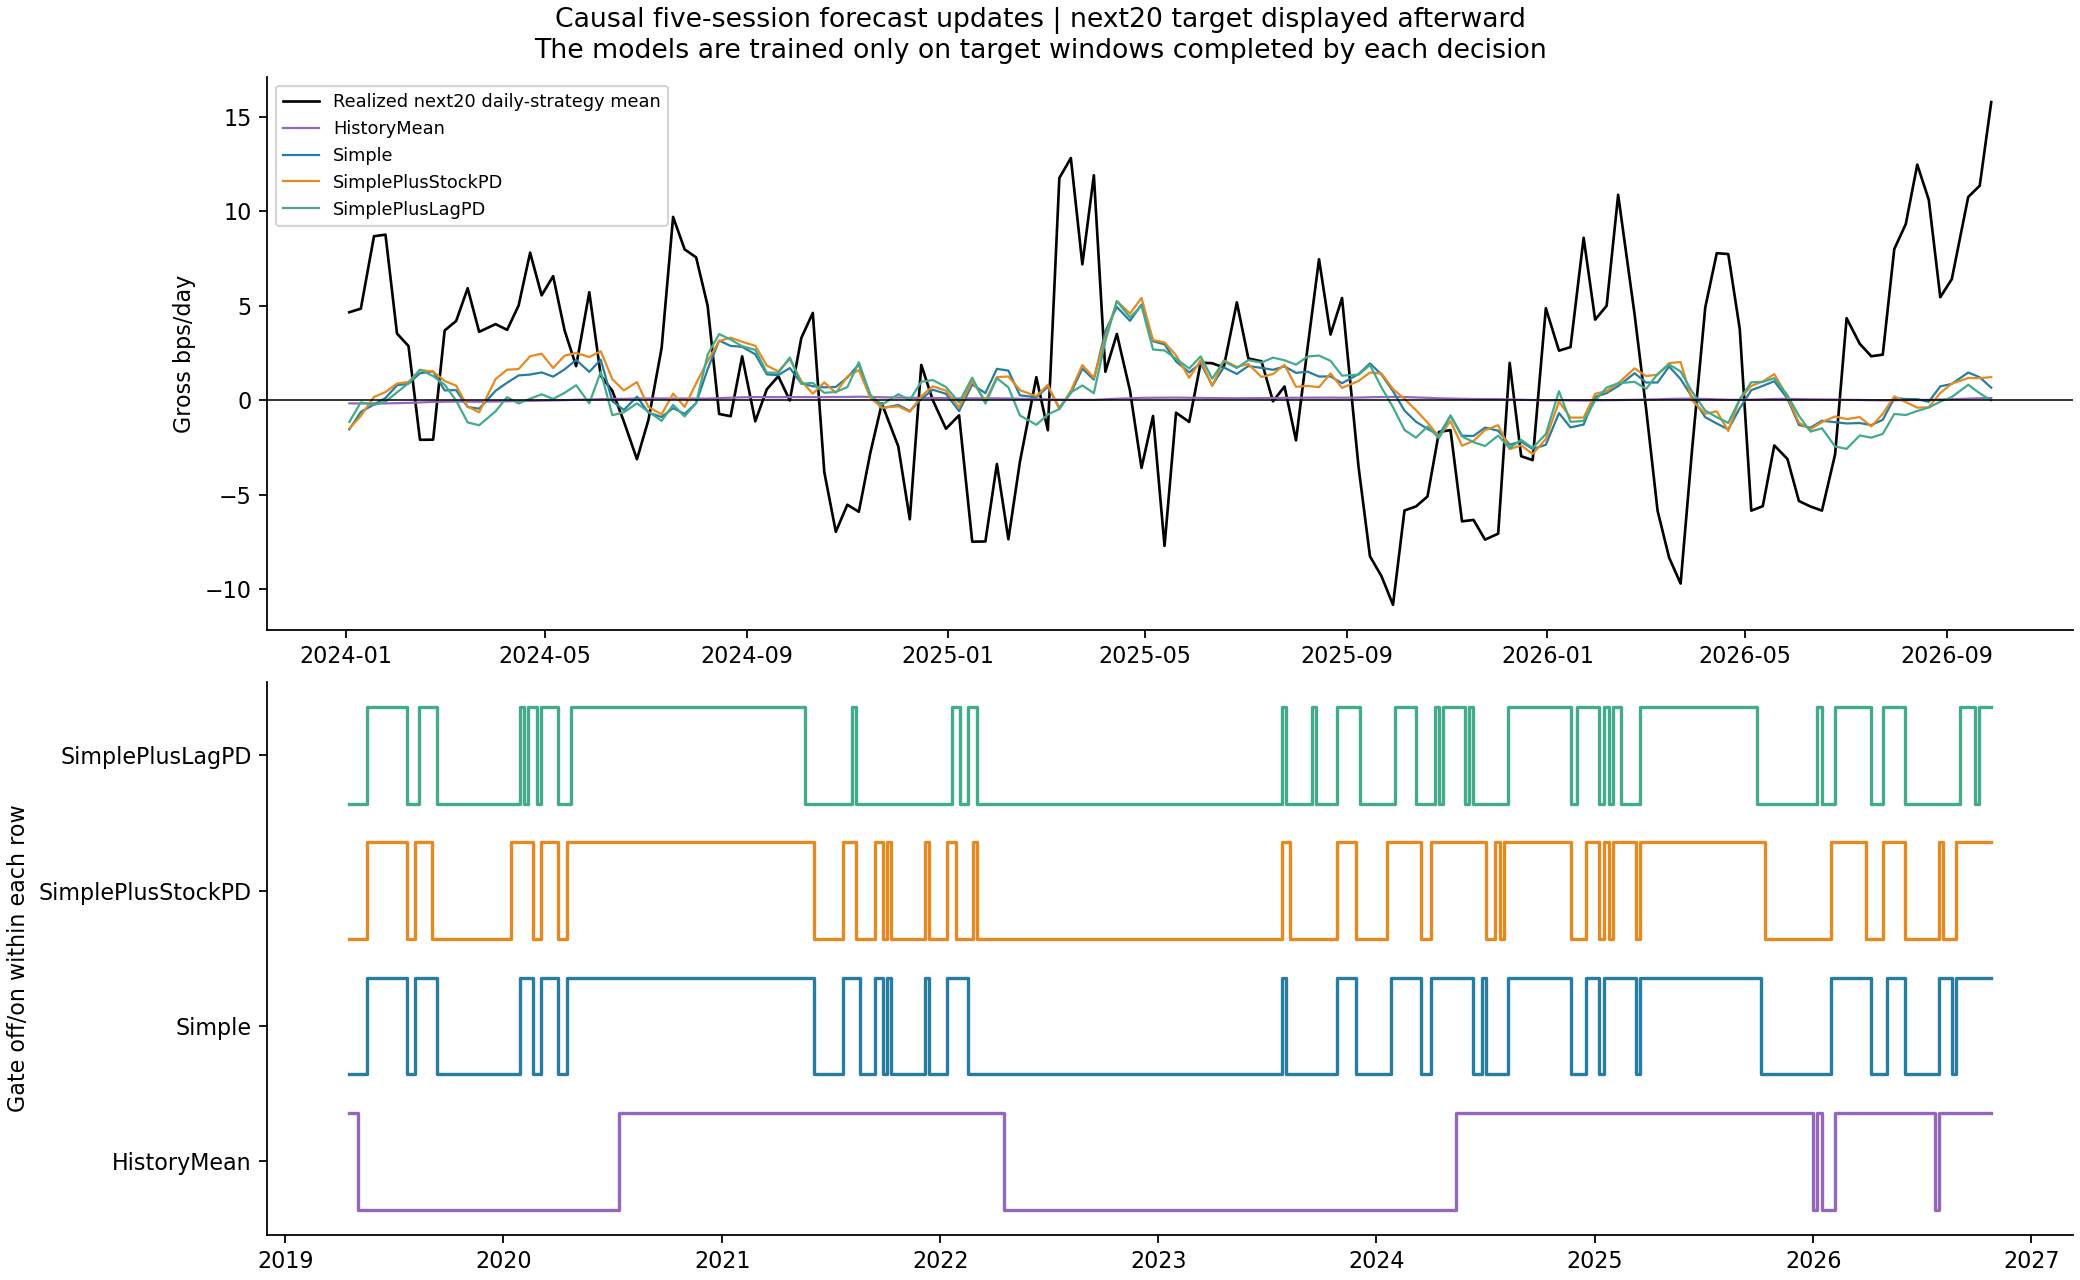

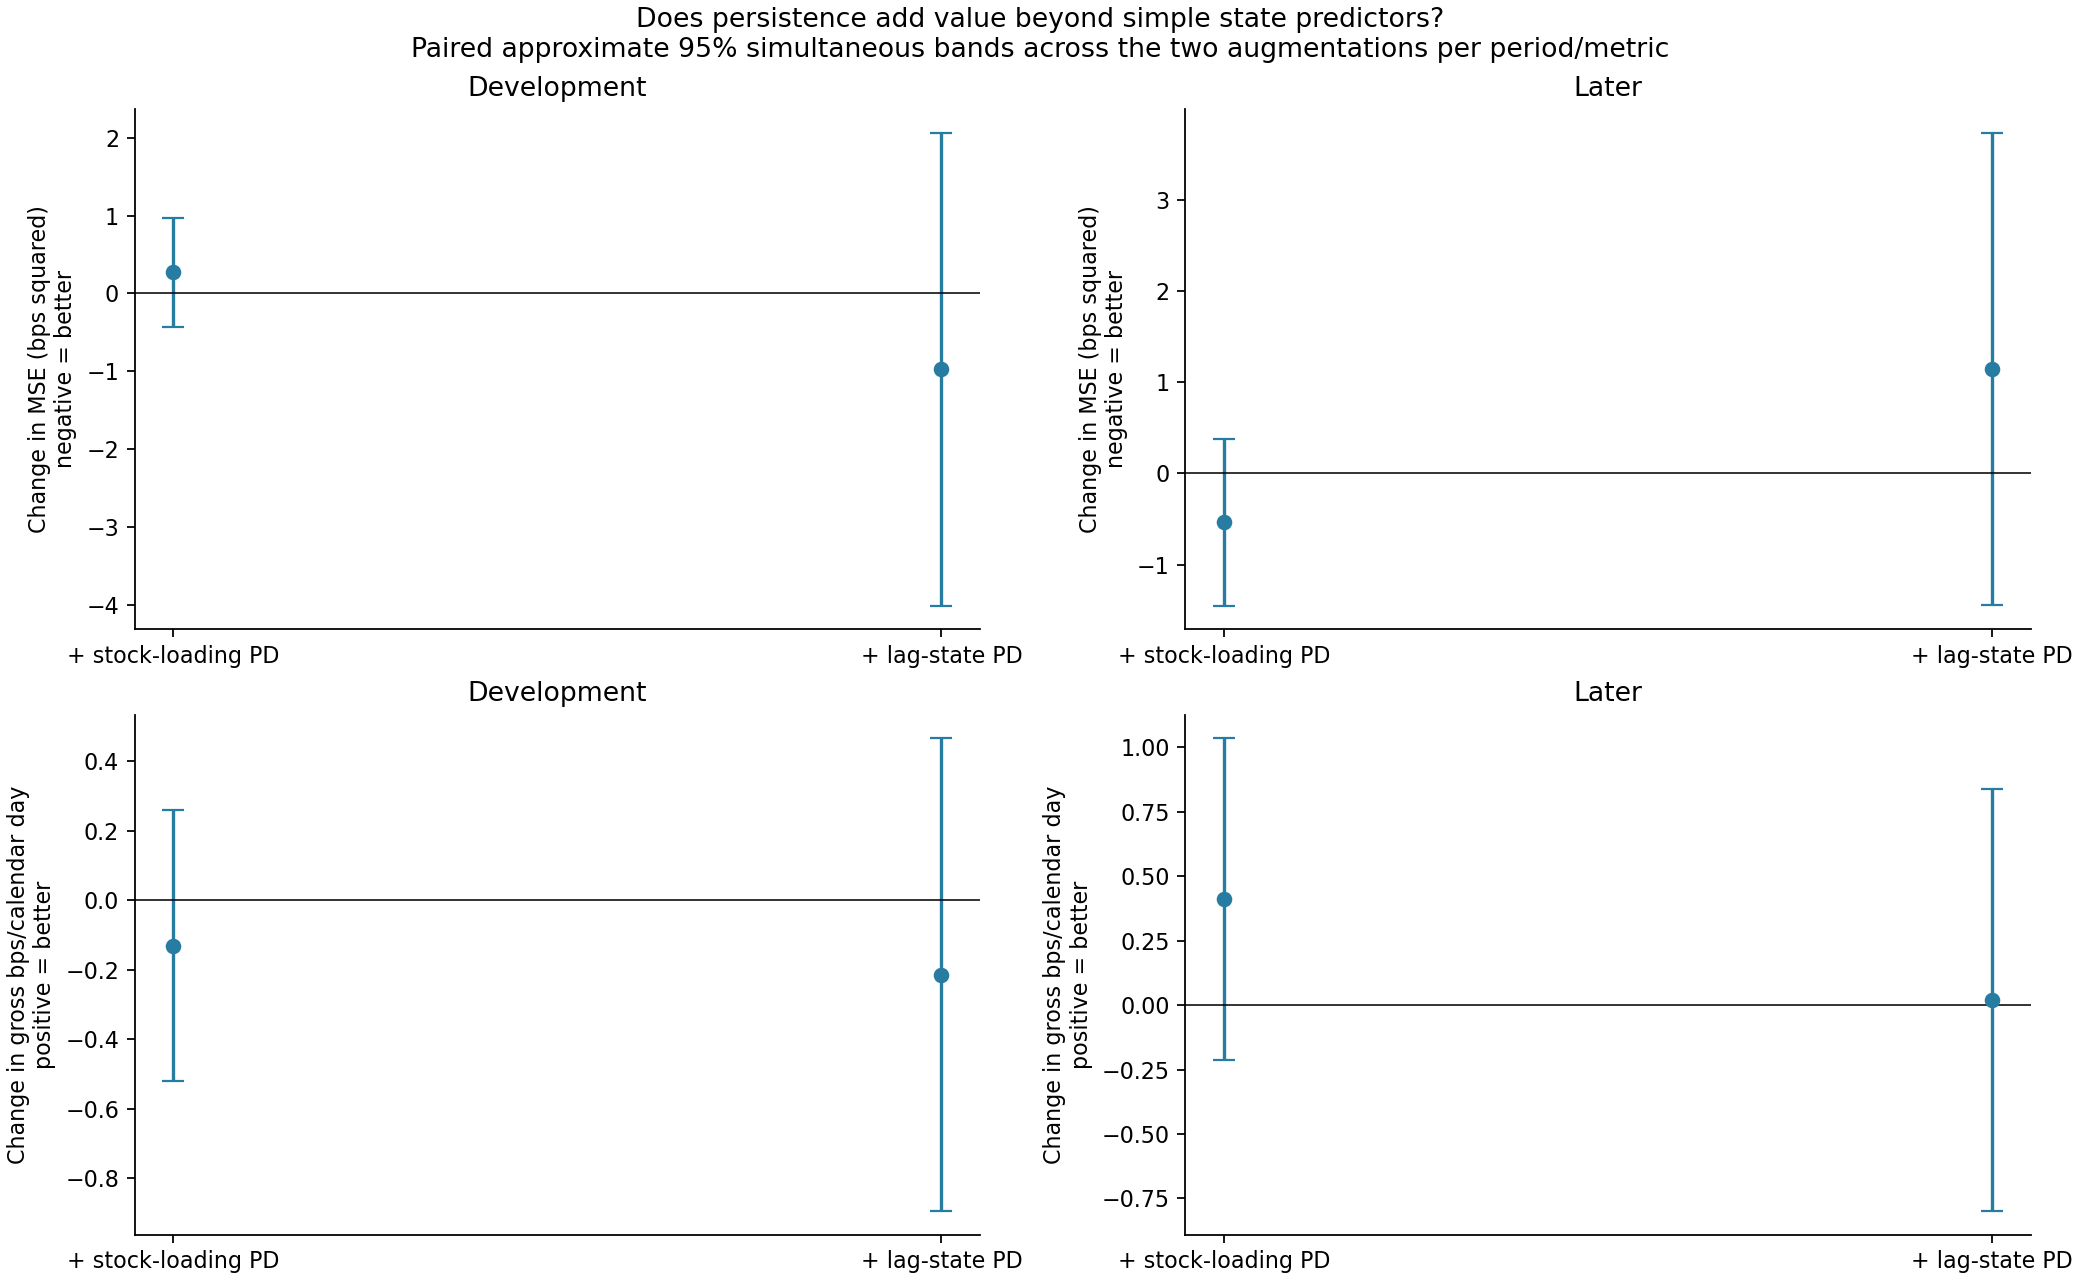

,period,comparison,metric,count,difference,point95_low,point95_high,sim95_low,sim95_high,better_direction
0,development,SimplePlusStockPD_minus_Simple,forecast_MSE_bps_squared,233,0.26989,-0.34525,0.87664,-0.43286,0.97263,negative
1,development,SimplePlusLagPD_minus_Simple,forecast_MSE_bps_squared,233,-0.97438,-3.39618,1.95891,-4.00970,2.06093,negative
2,development,SimplePlusStockPD_minus_Simple,gate_mean_bps_per_calendar_day,1183,-0.13064,-0.51171,0.15324,-0.52068,0.25939,positive
3,development,SimplePlusLagPD_minus_Simple,gate_mean_bps_per_calendar_day,1183,-0.21421,-0.84427,0.32680,-0.89513,0.46671,positive
4,later,SimplePlusStockPD_minus_Simple,forecast_MSE_bps_squared,138,-0.53549,-1.32563,0.21901,-1.45207,0.38110,negative
5,later,SimplePlusLagPD_minus_Simple,forecast_MSE_bps_squared,138,1.14549,-0.93677,3.47633,-1.44577,3.73675,negative
6,later,SimplePlusStockPD_minus_Simple,gate_mean_bps_per_calendar_day,708,0.41093,-0.08859,0.99009,-0.21308,1.03493,positive
7,later,SimplePlusLagPD_minus_Simple,gate_mean_bps_per_calendar_day,708,0.01993,-0.69717,0.76297,-0.79907,0.83893,positive


In [4]:
display(forecast.round(5))
display(Image(filename=str(out/"03_forecasts_and_gate_states.png")))
display(Image(filename=str(out/"02_incremental_comparisons.png")))
display(comparisons.round(5))
assert ((comparisons.sim95_low<0)&(comparisons.sim95_high>0)).all()

## 4. Does the active/flat gate improve trading?

Every rule uses the same matched daily calendar. When active, it uses exactly the original unit-gross positions; when flat, return is zero. There are no overlapping unit-gross cohorts or active-days-only performance averages.

Later point means are **1.343 bps/day always on**, **0.933 Simple**, **1.344 with stock PD**, and **0.953 with lag PD**. Stock PD is active about 69% of days and has lower observed volatility than always on. Its higher point Sharpe is a descriptive risk/return result, not a validated superiority claim.

The primary incremental comparisons are **stock PD minus Simple +0.411 bps/day**, approximate simultaneous interval **[-0.213,+1.035]**, and **lag PD minus Simple +0.020**, interval **[-0.799,+0.839]**. Both include zero. Development comparisons also include zero, and every calendar-mean interval includes zero.

Simultaneous intervals cover the two declared PD augmentations within each period/metric, not all preprocessing or historical research decisions. They resample saved causal outcomes in blocks; they do not refit forecasting models within each bootstrap.

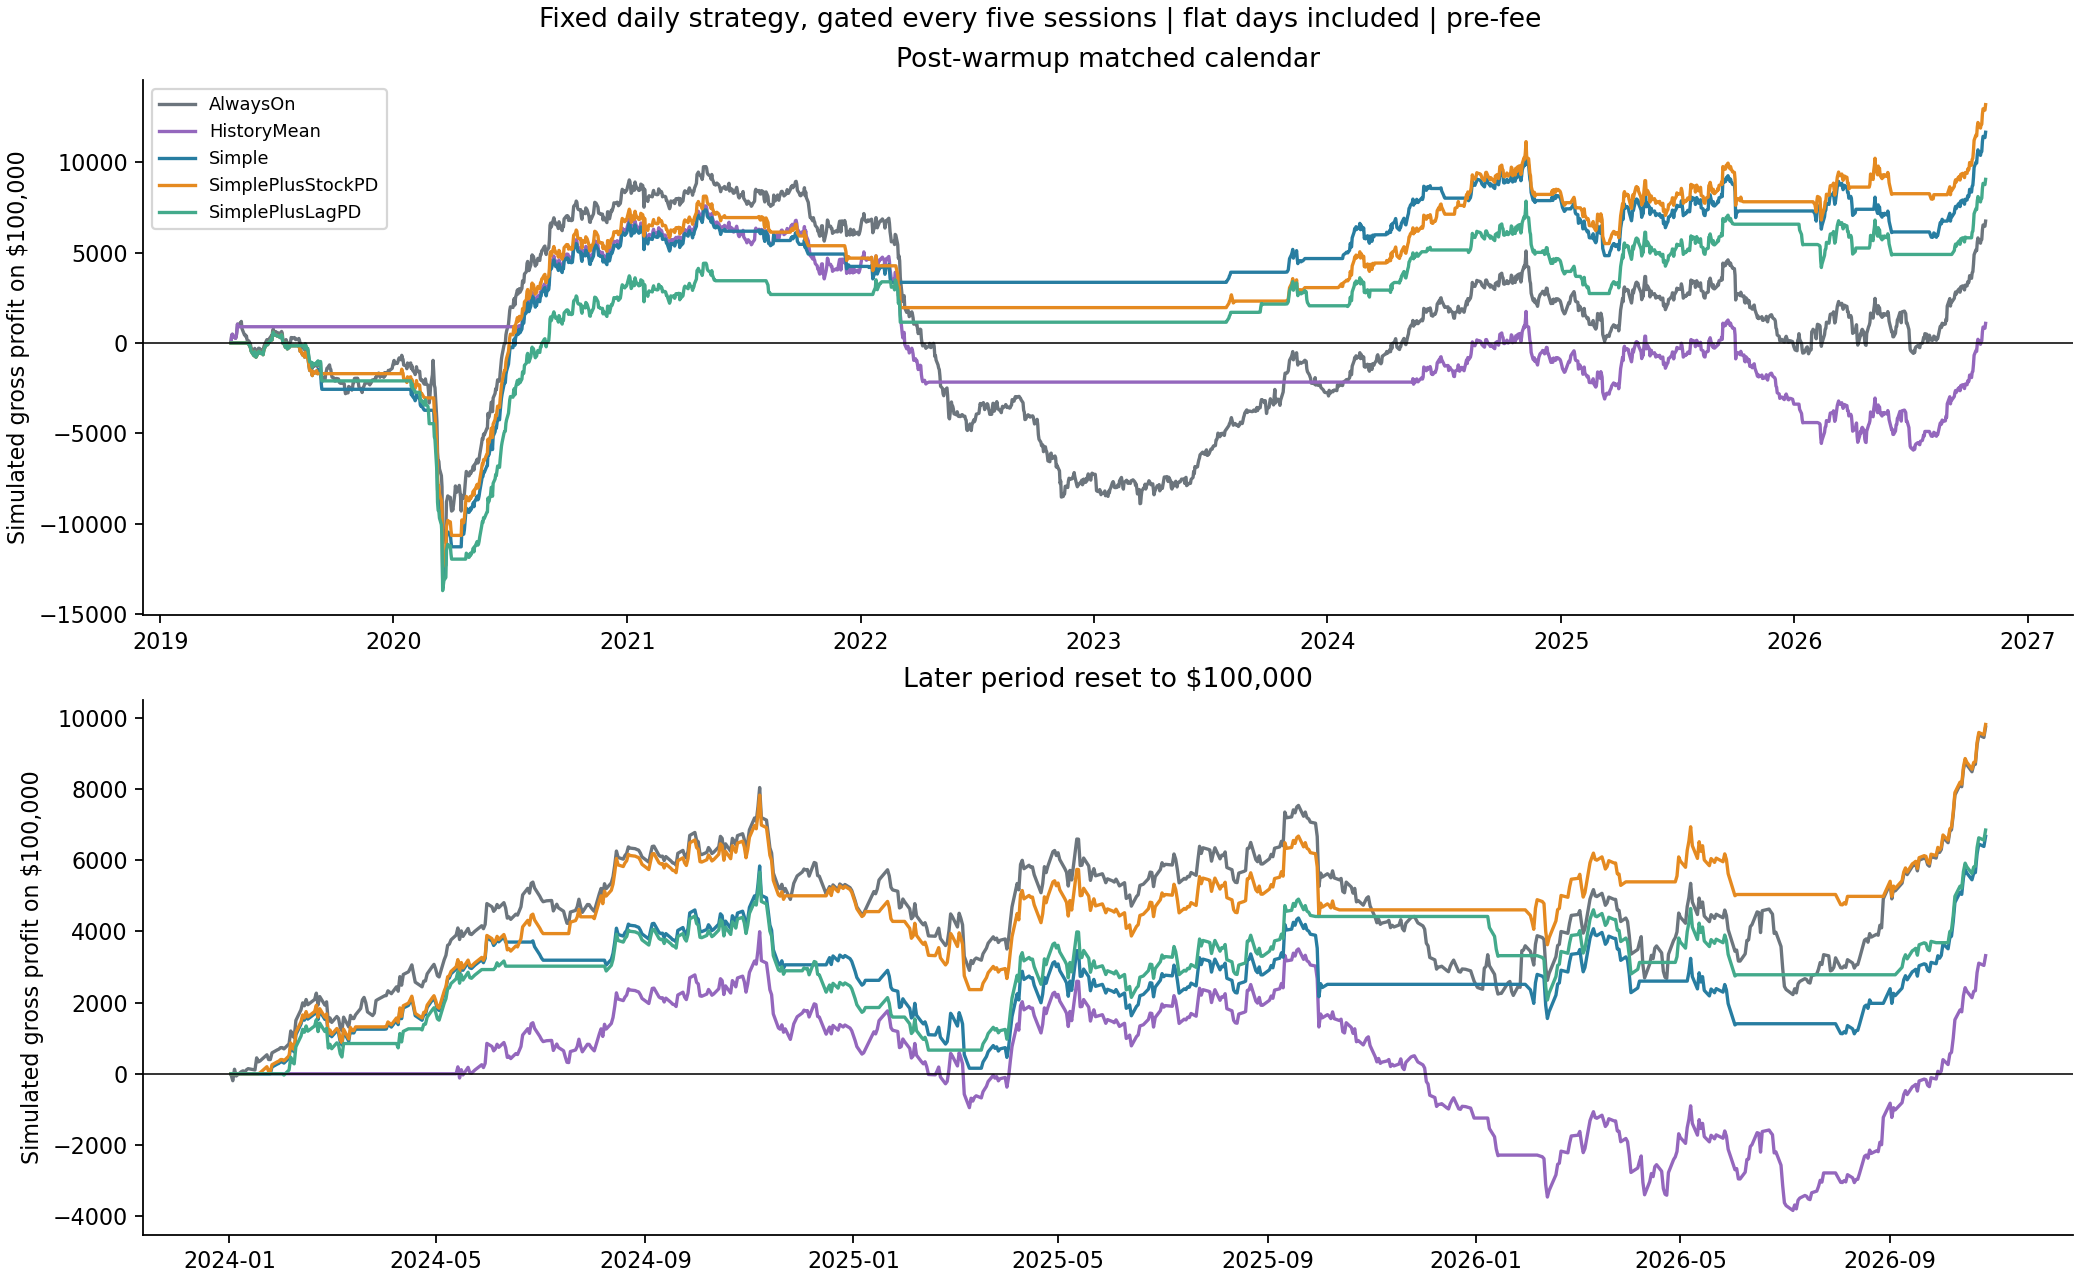

,period,model,calendar_days,active_fraction,mean_daily_bps,mean_low,mean_high,annualized_volatility,sharpe_vs_zero,gross_CAGR,total_gross_return,max_drawdown
0,development,AlwaysOn,1183,1.00000,-0.19734,-2.86554,2.73225,0.04344,-0.11448,-0.00590,-0.02740,-0.16987
1,development,HistoryMean,1183,0.38462,-0.17481,-1.52484,0.92258,0.02265,-0.19447,-0.00465,-0.02165,-0.09157
2,development,Simple,1183,0.40575,0.40692,-1.75487,2.93185,0.03254,0.31517,0.00977,0.04670,-0.13545
3,development,SimplePlusStockPD,1183,0.40152,0.27628,-1.88695,2.81360,0.03274,0.21265,0.00644,0.03061,-0.12931
4,development,SimplePlusLagPD,1183,0.36348,0.19270,-2.17579,2.58715,0.03213,0.15112,0.00435,0.02057,-0.14210
5,later,AlwaysOn,708,1.00000,1.34269,-0.73019,3.23508,0.03802,0.88996,0.03367,0.09749,-0.05410
6,later,HistoryMean,708,0.83475,0.48597,-1.47162,2.30200,0.03524,0.34751,0.01169,0.03320,-0.07538
7,later,Simple,708,0.67232,0.93278,-0.69932,2.61325,0.03181,0.73902,0.02327,0.06675,-0.05374
8,later,SimplePlusStockPD,708,0.69350,1.34371,-0.25943,2.84071,0.03205,1.05644,0.03391,0.09822,-0.05073
9,later,SimplePlusLagPD,708,0.58051,0.95271,-0.56708,2.41937,0.02886,0.83184,0.02387,0.06853,-0.04738


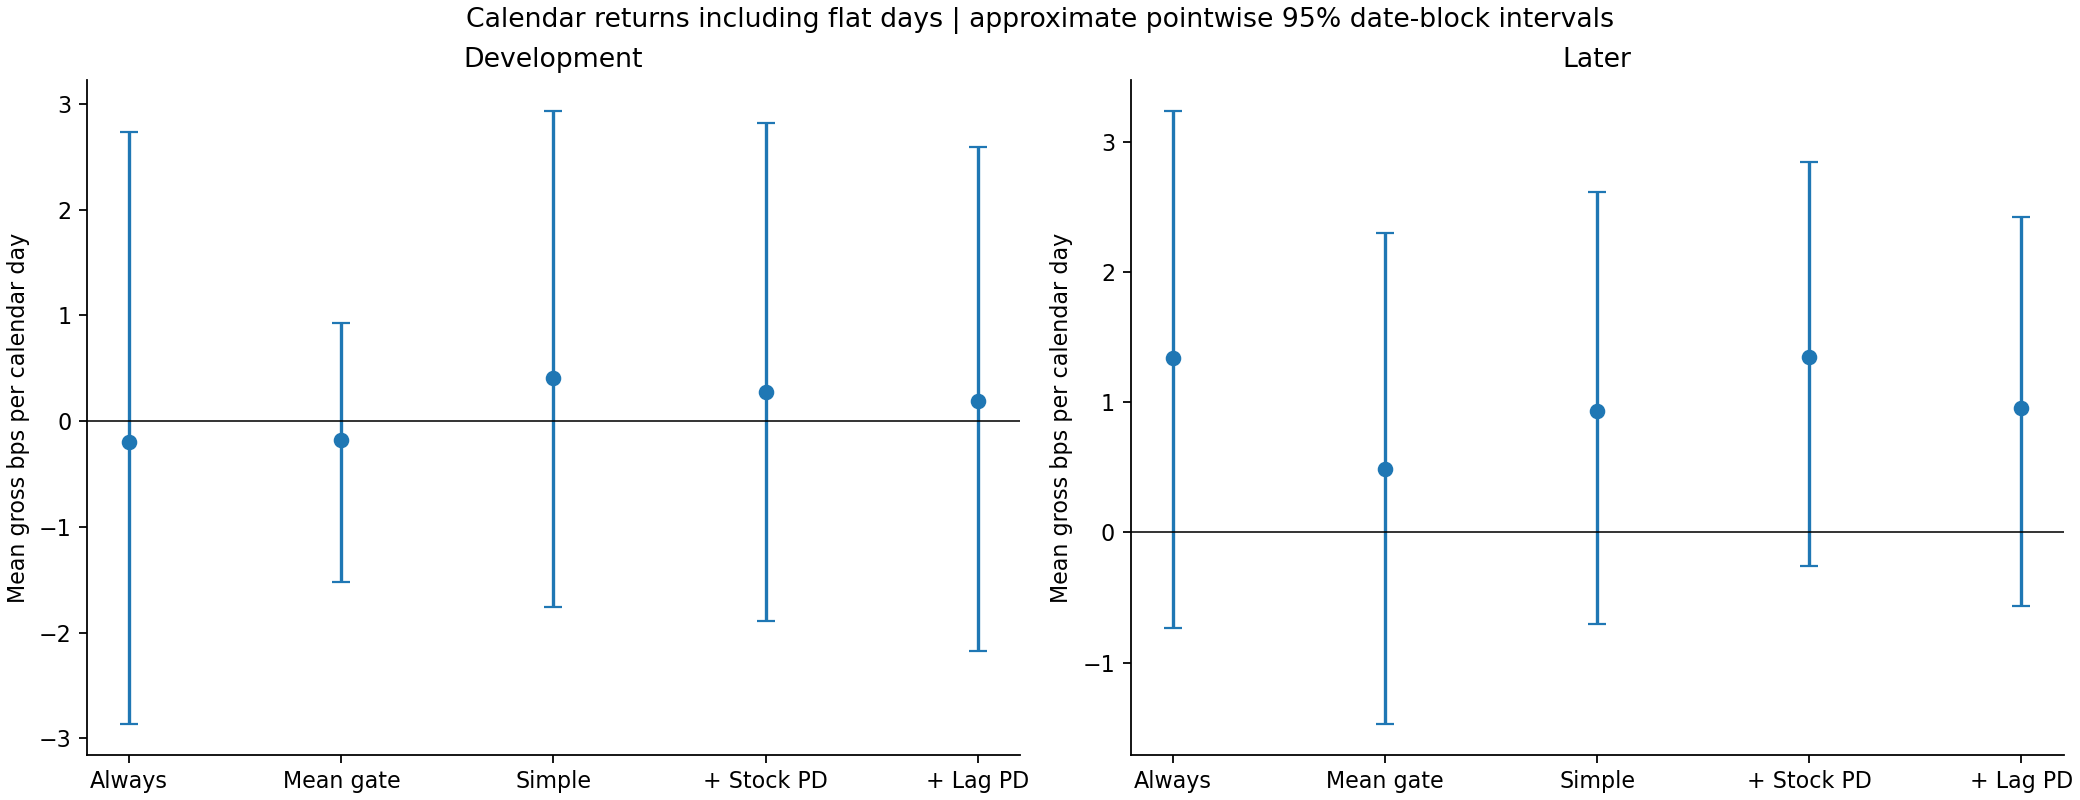

In [5]:
display(Image(filename=str(out/"01_gross_gate_profit.png")))
display(performance.round(5))
display(Image(filename=str(out/"04_calendar_mean_returns.png")))
assert ((performance.mean_low<0)&(performance.mean_high>0)).all()

## 5. Did favorable/unfavorable forecasts separate later outcomes?

Later Simple forecasts above zero correspond to a realized next20 mean of **1.156 bps/day**, versus **1.113** when nonpositive: almost no separation. Stock PD separates **1.241 versus 0.923**; lag PD gives **0.583 versus 1.890**, the opposite desired ordering. These conditional target means overlap in time and have wide uncertainty.

The historical-mean rule also missed favorable later windows while forecasting nonpositive returns. That is a failure diagnostic, not a reason to invert its sign after inspecting the outcome. We did not select a profitable cluster or change a threshold from this table.

In [6]:
display(calibration.round(5))
print("Incomplete latest forecast labels:",int(predictions.target_mean_bps.isna().sum()))
print("They remain unscored, but available daily executions are included.")

Incomplete latest forecast labels: 4
They remain unscored, but available daily executions are included.


,period,model,forecast_sign,forecasts,mean_prediction_bps,mean_future_target_bps,target_low,target_high
0,development,HistoryMean,positive,91,0.59118,-0.98637,-4.66449,1.69853
1,development,HistoryMean,nonpositive,142,-0.39434,0.30697,-3.04237,4.01316
2,development,Simple,positive,96,3.49869,1.65043,-2.57389,5.62956
3,development,Simple,nonpositive,137,-1.91214,-1.49352,-4.29509,1.03838
4,development,SimplePlusStockPD,positive,95,3.57026,1.77824,-2.47996,5.95973
5,development,SimplePlusStockPD,nonpositive,138,-1.88741,-1.55872,-4.19494,0.97650
6,development,SimplePlusLagPD,positive,86,3.28041,1.33801,-3.99160,5.96886
7,development,SimplePlusLagPD,nonpositive,147,-2.01611,-1.09686,-3.58043,1.11805
8,later,HistoryMean,positive,115,0.09153,0.48081,-1.29684,2.52512
9,later,HistoryMean,nonpositive,23,-0.07315,4.44709,3.46605,5.67561


## 6. What we can conclude

The two geometries preserve different measured distinctions. Neither supplies a demonstrated incremental profitability filter under this fixed learner and target. Stock-loading features have a modest favorable later trading estimate, while lagged states do not provide a convincing improvement here. A useful distinction in a representation is not automatically a useful forecast.

Keep this as the first bounded regime benchmark. Further work needs a specific reason a new representation should identify the strategy's conditional mean beyond the existing controls, rather than a search across lags, features, penalties, and thresholds on the same history.

Limitations include the survivor universe, fixed reference subset, overlapping labels, persistent state windows, approximate block inference, expanding later-period training, and already examined dates. No fees were deducted. Original strategy and data artifacts remain unchanged.

In [7]:
for name,passed in audit["checks"].items():
    print(name,passed)
print("Forecasts independently reproduced:",audit["forecast_rows_checked"])
print("Calendar rows independently checked:",audit["daily_calendar_rows_checked"])
print("Maximum independent forecast error, bps:",audit["max_independent_forecast_error_bps"])
assert all(audit["checks"].values())

reference_membership_formed_at_first_past_window True
all_features_targets_and_trailing_strategy_chronology_checked True
nine_feature_windows_reconstructed_from_covariance_eigenvectors True
H0_summaries_match_MST_and_essential_intervals_excluded True
all_saved_diagram_summaries_reconciled True
all_training_memberships_use_only_completed_prior_labels True
all_forecasts_scalers_and_coefficients_match_independent_sklearn_ridge True
uncompleted_future_label_perturbations_do_not_change_predictions True
all_daily_gates_and_zero_flat_days_reproduce True
all_forecast_and_gate_intervals_and_paired_simultaneous_bands_reproduce True
all_sign_calibration_counts_means_and_conditional_intervals_reproduce True
prior_inputs_and_results_unchanged True
Forecasts independently reproduced: 379
Calendar rows independently checked: 1891
Maximum independent forecast error, bps: 4.263256414560601e-14
